In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix, roc_curve

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.width', 200)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the data

The two files are the final preprocessed train and test sets. Each has 25 PCA columns (`PC01` to `PC25`) and a `target` column where **1 = phishing** and **0 = legitimate**.

We split each file into `X` (the 25 features) and `y` (the target).

In [ ]:
train = pd.read_csv('preprocessed_train_pca.csv')
test = pd.read_csv('preprocessed_test_pca.csv')

features = [c for c in train.columns if c != 'target']

X_train = train[features].values
y_train = train['target'].values
X_test = test[features].values
y_test = test['target'].values

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head()

Train shape: (47875, 26)
Test shape : (11970, 26)


,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,target
0,-4.603128,1.678861,-1.419249,-1.099112,-0.967836,0.187391,0.095995,3.000505,0.446165,0.621242,...,0.124783,-0.245364,0.383272,0.417093,-0.487010,0.919774,-0.115191,-0.419539,-0.655163,0
1,1.777175,10.458797,-1.632330,0.115482,1.847320,-0.461765,-0.568795,2.357430,1.434092,-2.175945,...,0.550571,-0.415791,0.757650,-0.529878,-0.563746,-0.074933,-0.547493,1.254218,0.163475,1
2,5.566793,0.931760,-1.902135,4.107839,-0.810134,0.808116,2.565517,-2.842359,0.895604,2.708044,...,-1.598353,-1.051824,-1.210126,-1.659753,-0.250925,0.266706,0.430985,-0.184668,-0.269085,1
3,0.587602,7.742090,-1.166531,1.488328,2.433178,-0.530288,-0.462300,1.469684,1.280535,-2.950102,...,-1.005752,1.322223,0.025105,-1.082447,-0.849874,0.573380,-0.731772,0.120409,-0.051969,1
4,-4.448724,1.010137,-0.602875,-0.632315,-0.613366,0.262325,0.426372,3.015591,0.507760,0.768383,...,-0.531365,0.306382,0.083267,0.382225,-0.274019,0.736406,0.318651,-0.622345,-0.832435,0


## 3. Basic data checks

We check two things:
- **Missing values** — XGBoost can handle them, but we want to know if there are any.
- **Class balance** — if one class is much bigger, accuracy alone would be misleading.

Missing values in train: 0
Missing values in test : 0
         train    test
target                
1       0.5262  0.5261
0       0.4738  0.4739


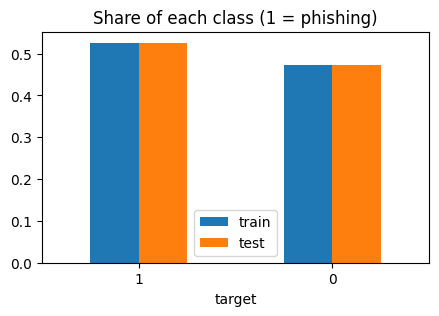

In [ ]:
print('Missing values in train:', train.isna().sum().sum())
print('Missing values in test :', test.isna().sum().sum())

balance = pd.DataFrame({
    'train': train['target'].value_counts(normalize=True),
    'test': test['target'].value_counts(normalize=True)
})
print(balance.round(4))

balance.plot(kind='bar', figsize=(5, 3))
plt.title('Share of each class (1 = phishing)')
plt.xticks(rotation=0)
plt.show()

## 4. Duplicate rows

Many URLs can produce exactly the same feature values, so the training data contains **duplicate rows**.

Why this matters: if we use normal cross-validation, the same row can land in both the training part and the validation part. The model then "remembers" it and the score looks better than it really is.

To avoid this, we give every group of identical rows a **group id**. Later, validation will keep each group together on one side.

We also check whether any test rows are identical to training rows.

In [ ]:
train_keys = train[features].round(6).astype(str).apply('|'.join, axis=1)
test_keys = test[features].round(6).astype(str).apply('|'.join, axis=1)

groups = pd.factorize(train_keys)[0]

print('Duplicate rows in train:', train.duplicated().sum())
print('Number of unique feature rows in train:', len(set(train_keys)))

label_check = train.assign(key=train_keys).groupby('key')['target'].nunique()
print('Duplicate groups with conflicting labels:', (label_check > 1).sum())

print('Test rows that also appear in train:', test_keys.isin(set(train_keys)).sum(), 'out of', len(test))

Duplicate rows in train: 4540
Number of unique feature rows in train: 43333
Duplicate groups with conflicting labels: 0
Test rows that also appear in train: 78 out of 11970


## 5. How strong is each feature on its own?

Before modelling, we measure how well **each single feature** separates phishing from legitimate pages, using ROC-AUC (0.5 = useless, 1.0 = perfect).

This tells us how hard the problem is and helps us understand what the models will do.

PC01    0.9928
PC06    0.7176
PC07    0.6599
PC03    0.6517
PC04    0.5993
PC21    0.5734
PC08    0.5696
PC18    0.5694
dtype: float64


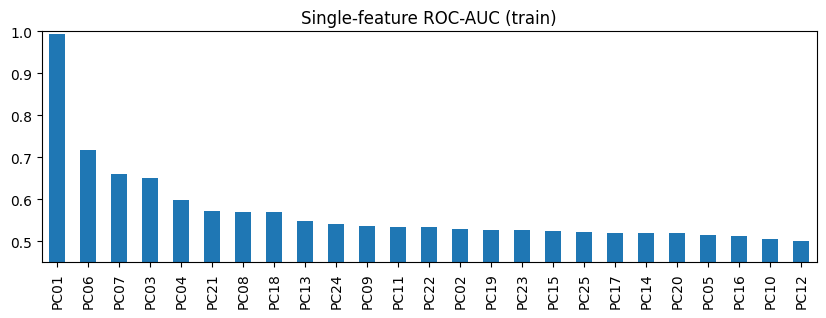

In [ ]:
single_aucs = []
for name in features:
    auc = roc_auc_score(y_train, train[name])
    single_aucs.append(max(auc, 1 - auc))

single = pd.Series(single_aucs, index=features).sort_values(ascending=False)
print(single.head(8).round(4))

single.plot(kind='bar', figsize=(10, 3))
plt.ylim(0.45, 1.0)
plt.title('Single-feature ROC-AUC (train)')
plt.show()

**What this shows:** `PC01` alone is already an almost perfect separator, and the other components add smaller improvements.

That means the problem is very close to **linearly separable**. So models with a simple, smooth decision boundary (like Logistic Regression) will be very strong, and tree models need careful tuning to match them. We keep this in mind for the rest of the notebook.

It is also a warning: scores near 100% on this data may come from how the dataset was built, so the real test of the project is on freshly collected URLs.

## 6. Validation setup (5-fold, group-aware)

We use **StratifiedGroupKFold** with 5 folds on the training data:
- *Stratified*: each fold keeps the same phishing/legitimate ratio.
- *Group*: identical rows stay together in the same fold (no leakage).

We build the folds once and reuse them for every model, so all comparisons are fair.

In [ ]:
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train, groups))

for i, (tr_idx, va_idx) in enumerate(folds):
    print('Fold', i + 1, '- train rows:', len(tr_idx), '- validation rows:', len(va_idx))

Fold 1 - train rows: 38300 - validation rows: 9575
Fold 2 - train rows: 38300 - validation rows: 9575
Fold 3 - train rows: 38300 - validation rows: 9575
Fold 4 - train rows: 38300 - validation rows: 9575
Fold 5 - train rows: 38300 - validation rows: 9575


## 7. Helper functions for validation

These small functions train a model on 4 folds and predict the 5th, five times. The collected predictions are called **out-of-fold (OOF) predictions**: every training row is predicted by a model that never saw it. We then score the whole set at once.

- `oof_logreg` — Logistic Regression.
- `oof_default_xgb` — XGBoost with default-style settings (our baseline).
- `oof_xgb` — XGBoost with given settings and **early stopping**: training stops when the validation loss stops improving, and we remember how many trees were really needed.
- `oof_lr_xgb` — the stronger idea: first fit a Logistic Regression, then let XGBoost fix **only its remaining mistakes**. Technically, the Logistic Regression output is given to XGBoost as the starting point (`base_margin`).

Note: early stopping uses the validation fold, which makes the CV score very slightly optimistic. This affects all tuned models equally, and the final test set is untouched.

In [ ]:
def oof_logreg(C):
    oof = np.zeros(len(y_train))
    for tr_idx, va_idx in folds:
        model = LogisticRegression(C=C, max_iter=3000)
        model.fit(X_train[tr_idx], y_train[tr_idx])
        oof[va_idx] = model.predict_proba(X_train[va_idx])[:, 1]
    return oof


def oof_default_xgb():
    oof = np.zeros(len(y_train))
    for tr_idx, va_idx in folds:
        model = XGBClassifier(n_estimators=300, tree_method='hist', n_jobs=1, random_state=42)
        model.fit(X_train[tr_idx], y_train[tr_idx])
        oof[va_idx] = model.predict_proba(X_train[va_idx])[:, 1]
    return oof


def oof_xgb(params):
    oof = np.zeros(len(y_train))
    rounds_list = []
    for tr_idx, va_idx in folds:
        model = XGBClassifier(n_estimators=3000, tree_method='hist', n_jobs=1, eval_metric='logloss',
                              early_stopping_rounds=40, random_state=42, **params)
        model.fit(X_train[tr_idx], y_train[tr_idx], eval_set=[(X_train[va_idx], y_train[va_idx])], verbose=False)
        oof[va_idx] = model.predict_proba(X_train[va_idx])[:, 1]
        rounds_list.append(model.best_iteration + 1)
    return oof, int(np.mean(rounds_list))


margin_cache = {}

def get_margins(C):
    if C not in margin_cache:
        result = []
        for tr_idx, va_idx in folds:
            lr = LogisticRegression(C=C, max_iter=3000)
            lr.fit(X_train[tr_idx], y_train[tr_idx])
            result.append((lr.decision_function(X_train[tr_idx]), lr.decision_function(X_train[va_idx])))
        margin_cache[C] = result
    return margin_cache[C]


def make_lr_xgb_params(p):
    return {
        'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'nthread': 1, 'seed': 42,
        'eta': p['eta'], 'max_depth': p['max_depth'], 'min_child_weight': p['min_child_weight'],
        'gamma': p['gamma'], 'subsample': p['subsample'], 'colsample_bytree': p['colsample_bytree'],
        'reg_lambda': p['reg_lambda'], 'reg_alpha': p['reg_alpha']
    }


def oof_lr_xgb(p):
    margins = get_margins(p['C'])
    params = make_lr_xgb_params(p)
    oof = np.zeros(len(y_train))
    rounds_list = []
    for i, (tr_idx, va_idx) in enumerate(folds):
        dtrain = xgb.DMatrix(X_train[tr_idx], label=y_train[tr_idx], base_margin=margins[i][0])
        dval = xgb.DMatrix(X_train[va_idx], label=y_train[va_idx], base_margin=margins[i][1])
        booster = xgb.train(params, dtrain, 3000, evals=[(dval, 'val')], early_stopping_rounds=40, verbose_eval=False)
        oof[va_idx] = booster.predict(dval, iteration_range=(0, booster.best_iteration + 1))
        rounds_list.append(booster.best_iteration + 1)
    return oof, int(np.mean(rounds_list))


def score_oof(name, oof):
    pred = (oof > 0.5).astype(int)
    return {'model': name, 'log_loss': log_loss(y_train, oof), 'accuracy': accuracy_score(y_train, pred),
            'errors': int((pred != y_train).sum()), 'roc_auc': roc_auc_score(y_train, oof)}

## 8. Baselines

Two simple reference points, scored with the cross-validation above:
- default XGBoost,
- Logistic Regression.

Everything we tune later must beat these to be worth keeping. We report **log-loss** (lower is better; it also punishes over-confident mistakes), accuracy, number of wrong predictions, and ROC-AUC.

In [ ]:
oof_base_xgb = oof_default_xgb()
oof_base_lr = oof_logreg(10)

baseline_table = pd.DataFrame([
    score_oof('Default XGBoost', oof_base_xgb),
    score_oof('Logistic Regression (C=10)', oof_base_lr)
])
baseline_table.round(5)

,model,log_loss,accuracy,errors,roc_auc
0,Default XGBoost,0.01626,0.99618,183,0.99970
1,Logistic Regression (C=10),0.01156,0.99716,136,0.99972


## 9. Tune XGBoost with Optuna

Optuna tries many hyperparameter combinations and learns which regions work best. Each trial is scored by the **average log-loss across the 5 folds** (lower is better). A pruner stops clearly bad trials early to save time.

Settings we tune:
- `learning_rate`: step size of each tree,
- `max_depth`: how deep trees can grow,
- `min_child_weight`, `gamma`, `reg_lambda`, `reg_alpha`: regularization to avoid overfitting,
- `subsample`, `colsample_bytree`: random fraction of rows / columns per tree.

The number of trees is not tuned directly: early stopping picks it in every trial.

In [ ]:
def objective_xgb(trial):
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 1, 8),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 30, log=True),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.01, 50, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 10, log=True)
    }
    losses = []
    step = 0
    for tr_idx, va_idx in folds:
        model = XGBClassifier(n_estimators=3000, tree_method='hist', n_jobs=1, eval_metric='logloss',
                              early_stopping_rounds=40, random_state=42, **params)
        model.fit(X_train[tr_idx], y_train[tr_idx], eval_set=[(X_train[va_idx], y_train[va_idx])], verbose=False)
        losses.append(model.best_score)
        trial.report(float(np.mean(losses)), step)
        step = step + 1
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(losses))


study_xgb = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1)
)
study_xgb.enqueue_trial({'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1, 'gamma': 0,
                         'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.001})
study_xgb.optimize(objective_xgb, n_trials=40)

print('Best CV log-loss:', round(study_xgb.best_value, 5))
print('Best parameters:')
for k, v in study_xgb.best_params.items():
    print('  ', k, '=', round(v, 4))

Best CV log-loss: 0.01238
Best parameters:
   learning_rate = 0.0997
   max_depth = 3
   min_child_weight = 1.3942
   gamma = 0.1047
   subsample = 0.5489
   colsample_bytree = 0.631
   reg_lambda = 2.4072
   reg_alpha = 0.008


### Tuning progress

The chart shows each finished trial (dots) and the best score so far (line). A flattening line means more trials would bring little extra gain.

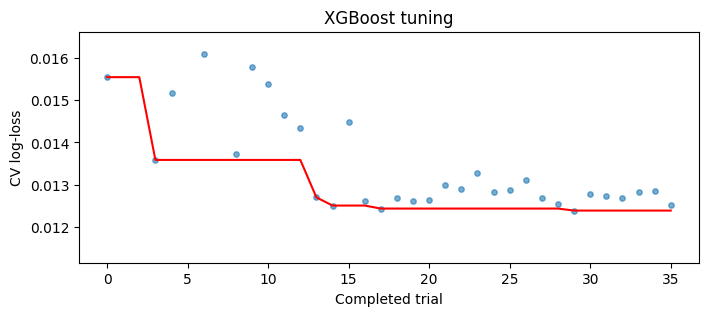

In [ ]:
done = [t for t in study_xgb.trials if t.state.name == 'COMPLETE']
values = [t.value for t in done]
best_so_far = np.minimum.accumulate(values)

plt.figure(figsize=(8, 3))
plt.scatter(range(len(values)), values, s=15, alpha=0.6)
plt.plot(best_so_far, color='red')
plt.ylim(min(values) * 0.9, np.percentile(values, 90))
plt.xlabel('Completed trial')
plt.ylabel('CV log-loss')
plt.title('XGBoost tuning')
plt.show()

## 10. Tune the stronger model: Logistic Regression + XGBoost

The data is almost linear, but trees are not naturally good at straight diagonal boundaries. So we combine the two:
1. Logistic Regression draws the main straight boundary.
2. XGBoost learns the small curved corrections that the straight line misses.

We also tune `C` (the Logistic Regression strength; larger = less regularization) together with the XGBoost settings.

In [ ]:
def objective_lr_xgb(trial):
    p = {
        'C': trial.suggest_categorical('C', [0.3, 1, 3, 10, 30, 100]),
        'eta': trial.suggest_float('eta', 0.02, 0.15, log=True),
        'max_depth': trial.suggest_int('max_depth', 1, 5),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 30, log=True),
        'gamma': trial.suggest_float('gamma', 0, 3),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 50, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 10, log=True)
    }
    margins = get_margins(p['C'])
    params = make_lr_xgb_params(p)
    losses = []
    step = 0
    for i, (tr_idx, va_idx) in enumerate(folds):
        dtrain = xgb.DMatrix(X_train[tr_idx], label=y_train[tr_idx], base_margin=margins[i][0])
        dval = xgb.DMatrix(X_train[va_idx], label=y_train[va_idx], base_margin=margins[i][1])
        booster = xgb.train(params, dtrain, 3000, evals=[(dval, 'val')], early_stopping_rounds=40, verbose_eval=False)
        losses.append(booster.best_score)
        trial.report(float(np.mean(losses)), step)
        step = step + 1
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(losses))


study_lrx = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=7),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1)
)
study_lrx.enqueue_trial({'C': 10, 'eta': 0.05, 'max_depth': 3, 'min_child_weight': 3, 'gamma': 0.5,
                         'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 2, 'reg_alpha': 0.001})
study_lrx.optimize(objective_lr_xgb, n_trials=80)

print('Best CV log-loss:', round(study_lrx.best_value, 5))
print('Best parameters:')
for k, v in study_lrx.best_params.items():
    print('  ', k, '=', round(v, 4) if not isinstance(v, int) else v)

Best CV log-loss: 0.00919
Best parameters:
   C = 30
   eta = 0.0252
   max_depth = 5
   min_child_weight = 1.2864
   gamma = 0.1484
   subsample = 0.8492
   colsample_bytree = 0.9952
   reg_lambda = 5.8701
   reg_alpha = 0.0083


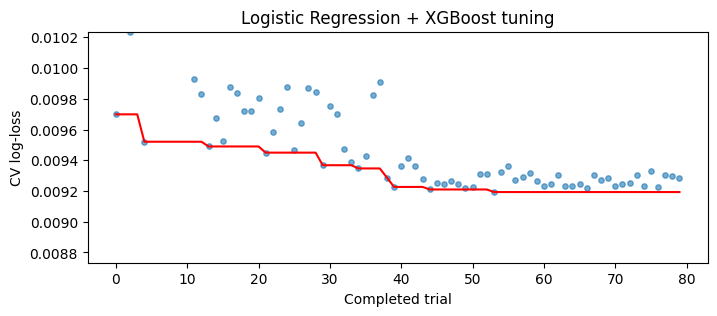

In [ ]:
done = [t for t in study_lrx.trials if t.state.name == 'COMPLETE']
values = [t.value for t in done]
best_so_far = np.minimum.accumulate(values)

plt.figure(figsize=(8, 3))
plt.scatter(range(len(values)), values, s=15, alpha=0.6)
plt.plot(best_so_far, color='red')
plt.ylim(min(values) * 0.95, np.percentile(values, 90))
plt.xlabel('Completed trial')
plt.ylabel('CV log-loss')
plt.title('Logistic Regression + XGBoost tuning')
plt.show()

## 11. Compare all models with cross-validation

Now we re-run the cross-validation with the best settings found, and put all four models in one table. This is the table we use to **choose the final model** — still without touching the test set.

`errors` is the number of wrong predictions out of all training rows.

In [ ]:
best_xgb_params = study_xgb.best_params
best_lrx_params = study_lrx.best_params

oof_tuned_xgb, rounds_xgb = oof_xgb(best_xgb_params)
oof_lr_plus_xgb, rounds_lrx = oof_lr_xgb(best_lrx_params)
oof_tuned_lr = oof_logreg(best_lrx_params['C'])

cv_table = pd.DataFrame([
    score_oof('Default XGBoost', oof_base_xgb),
    score_oof('Logistic Regression (tuned C)', oof_tuned_lr),
    score_oof('Tuned XGBoost', oof_tuned_xgb),
    score_oof('Logistic Regression + XGBoost', oof_lr_plus_xgb)
])
print('Trees needed - tuned XGBoost:', rounds_xgb, '| Logistic Regression + XGBoost:', rounds_lrx)
cv_table.round(5)

Trees needed - tuned XGBoost: 578 | Logistic Regression + XGBoost: 577


,model,log_loss,accuracy,errors,roc_auc
0,Default XGBoost,0.01626,0.99618,183,0.99970
1,Logistic Regression (tuned C),0.01117,0.99726,131,0.99971
2,Tuned XGBoost,0.01238,0.99645,170,0.99972
3,Logistic Regression + XGBoost,0.00919,0.99768,111,0.99977


## 12. Choose the decision threshold

By default we call a page phishing when its probability is above 0.5. But the best cut-off can be different. We test several thresholds using the **out-of-fold predictions** of the final model (not the test set) and count:
- **False positives (FP)**: legitimate pages wrongly flagged (annoying for users),
- **False negatives (FN)**: phishing pages we missed (dangerous).

We only move away from 0.5 if another threshold gives a clearly better result (at least 5 fewer errors). Otherwise a tiny gain could just be noise.

In [ ]:
rows = []
for t in np.arange(0.2, 0.81, 0.05):
    pred = (oof_lr_plus_xgb > t).astype(int)
    rows.append({'threshold': round(t, 2),
                 'errors': int((pred != y_train).sum()),
                 'false_positives': int(((pred == 1) & (y_train == 0)).sum()),
                 'false_negatives': int(((pred == 0) & (y_train == 1)).sum())})
threshold_table = pd.DataFrame(rows)
print(threshold_table.to_string(index=False))

errors_at_half = threshold_table.loc[threshold_table['threshold'] == 0.5, 'errors'].values[0]
best_row = threshold_table.sort_values('errors').iloc[0]

chosen_threshold = 0.5
if errors_at_half - best_row['errors'] >= 5:
    chosen_threshold = float(best_row['threshold'])

print()
print('Chosen threshold:', chosen_threshold)

 threshold  errors  false_positives  false_negatives
      0.20     123               64               59
      0.25     118               55               63
      0.30     119               50               69
      0.35     118               45               73
      0.40     117               41               76
      0.45     114               35               79
      0.50     111               29               82
      0.55     114               26               88
      0.60     113               22               91
      0.65     117               16              101
      0.70     123               12              111
      0.75     130               12              118
      0.80     142               12              130

Chosen threshold: 0.5


## 13. Train the final models on all training data

Now we train each final model on the **full training set** (no folds). The number of trees comes from early stopping in cross-validation, increased by 10% because the final model sees about 25% more data than each fold did.

We train:
- the **default XGBoost** (reference),
- the **tuned XGBoost** (standalone fallback),
- the **Logistic Regression + XGBoost** (our best model).

In [ ]:
default_model = XGBClassifier(n_estimators=300, tree_method='hist', n_jobs=1, random_state=42)
default_model.fit(X_train, y_train)

final_xgb = XGBClassifier(n_estimators=int(rounds_xgb * 1.1), tree_method='hist', n_jobs=1,
                          eval_metric='logloss', random_state=42, **best_xgb_params)
final_xgb.fit(X_train, y_train)

final_lr = LogisticRegression(C=best_lrx_params['C'], max_iter=3000)
final_lr.fit(X_train, y_train)

lrx_params = make_lr_xgb_params(best_lrx_params)
lrx_rounds = int(rounds_lrx * 1.1)
dtrain_final = xgb.DMatrix(X_train, label=y_train, base_margin=final_lr.decision_function(X_train))
final_booster = xgb.train(lrx_params, dtrain_final, num_boost_round=lrx_rounds)

print('Tuned XGBoost trees:', int(rounds_xgb * 1.1))
print('Logistic Regression + XGBoost trees:', lrx_rounds)

Tuned XGBoost trees: 635
Logistic Regression + XGBoost trees: 634


## 14. Final test-set evaluation (used once)

This is the only time we use the test set. For every model we report:
- **Accuracy**: share of correct predictions,
- **Precision**: of the pages we flagged as phishing, how many really were,
- **Recall**: of all real phishing pages, how many we caught,
- **F1**: balance of precision and recall,
- **ROC-AUC**: quality of the probability ranking, independent of the threshold,
- **Log-loss**: quality of the probabilities themselves,
- **FP / FN**: the two kinds of mistakes.

The threshold of 0.5 is used for the three reference models; the chosen threshold from step 12 is used for the final model.

In [ ]:
dtest_final = xgb.DMatrix(X_test, base_margin=final_lr.decision_function(X_test))

prob_default = default_model.predict_proba(X_test)[:, 1]
prob_lr = final_lr.predict_proba(X_test)[:, 1]
prob_xgb = final_xgb.predict_proba(X_test)[:, 1]
prob_final = final_booster.predict(dtest_final)


def test_scores(name, prob, threshold):
    pred = (prob > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'model': name, 'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred),
            'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred),
            'roc_auc': roc_auc_score(y_test, prob), 'log_loss': log_loss(y_test, prob),
            'FP': fp, 'FN': fn, 'errors': fp + fn}


test_table = pd.DataFrame([
    test_scores('Default XGBoost', prob_default, 0.5),
    test_scores('Logistic Regression', prob_lr, 0.5),
    test_scores('Tuned XGBoost', prob_xgb, 0.5),
    test_scores('Logistic Regression + XGBoost (final)', prob_final, chosen_threshold)
])
test_table.round(5)

,model,accuracy,precision,recall,f1,roc_auc,log_loss,FP,FN,errors
0,Default XGBoost,0.99708,0.99825,0.99619,0.99722,0.99961,0.01466,11,24,35
1,Logistic Regression,0.99783,0.99889,0.99698,0.99793,0.99985,0.00918,7,19,26
2,Tuned XGBoost,0.99708,0.99825,0.99619,0.99722,0.99969,0.01117,11,24,35
3,Logistic Regression + XGBoost (final),0.99841,0.99936,0.99762,0.99849,0.99983,0.00837,4,15,19


### Confusion matrix and ROC curve of the final model

The confusion matrix shows exactly how many pages of each type were classified correctly. The ROC curve shows the trade-off between catching phishing pages and wrongly flagging legitimate ones; the closer to the top-left corner, the better.

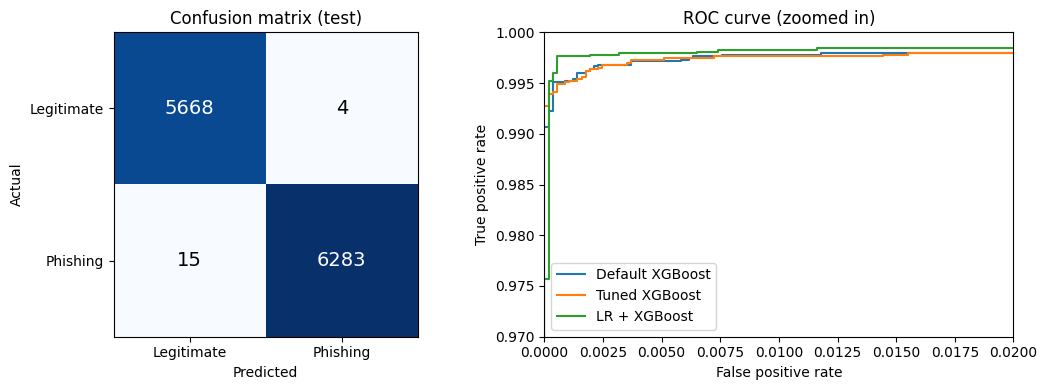

In [ ]:
pred_final = (prob_final > chosen_threshold).astype(int)
cm = confusion_matrix(y_test, pred_final)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Legitimate', 'Phishing'])
axes[0].set_yticklabels(['Legitimate', 'Phishing'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion matrix (test)')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')

for name, prob in [('Default XGBoost', prob_default), ('Tuned XGBoost', prob_xgb), ('LR + XGBoost', prob_final)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=name)
axes[1].set_xlim(0, 0.02)
axes[1].set_ylim(0.97, 1.0)
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve (zoomed in)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 15. Is the improvement real or just luck?

The test set has about 12,000 rows, so a difference of a few predictions can easily be noise. We use **bootstrapping**: we resample the test set 2,000 times and see how much the accuracy moves.

We compute:
1. a 95% interval for the accuracy of the final model,
2. the accuracy difference between the final model and the default XGBoost, with its 95% interval. If the interval includes 0, the improvement is not statistically clear.

In [ ]:
rng = np.random.default_rng(0)

correct_final = (pred_final == y_test).astype(int)
correct_default = ((prob_default > 0.5).astype(int) == y_test).astype(int)
correct_xgb = ((prob_xgb > 0.5).astype(int) == y_test).astype(int)

acc_final = []
diff_default = []
diff_xgb = []
for i in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    acc_final.append(correct_final[idx].mean())
    diff_default.append(correct_final[idx].mean() - correct_default[idx].mean())
    diff_xgb.append(correct_final[idx].mean() - correct_xgb[idx].mean())

low, high = np.percentile(acc_final, [2.5, 97.5])
print('Final model accuracy:', round(correct_final.mean(), 5), '- 95% interval:', round(low, 5), 'to', round(high, 5))

low, high = np.percentile(diff_default, [2.5, 97.5])
print('Gain vs default XGBoost:', round(np.mean(diff_default), 5), '- 95% interval:', round(low, 5), 'to', round(high, 5))

low, high = np.percentile(diff_xgb, [2.5, 97.5])
print('Gain vs tuned XGBoost :', round(np.mean(diff_xgb), 5), '- 95% interval:', round(low, 5), 'to', round(high, 5))

Final model accuracy: 0.99841 - 95% interval: 0.99758 to 0.99908
Gain vs default XGBoost: 0.00134 - 95% interval: 0.00058 to 0.00217
Gain vs tuned XGBoost : 0.00134 - 95% interval: 0.00058 to 0.00209


## 16. Error analysis

We look at the test rows the final model got wrong:
- How confident was the model when it was wrong? (very confident mistakes are the worrying ones)
- Which type of mistake is more common?
- Do these rows have an identical twin in the training data?

Total errors: 19
Missed phishing (FN): 15
Legitimate flagged as phishing (FP): 4
Errors with an identical row in train: 0


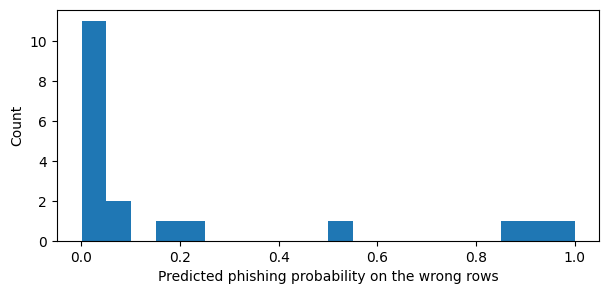

,target,predicted,probability,PC01,PC02,PC03
5964,1,0,0.000,-1.700,-2.808,-0.637
11544,1,0,0.001,-2.106,-0.551,-2.961
3506,1,0,0.002,-2.527,-3.639,3.589
5530,1,0,0.002,-2.589,-4.249,3.282
2631,1,0,0.006,-3.645,-0.913,0.677
6673,1,0,0.007,-2.867,-0.627,-0.673
8304,1,0,0.008,-3.501,-1.312,1.703
1522,1,0,0.013,-3.072,-2.830,3.654
11593,1,0,0.018,-3.291,-3.184,3.009
8302,1,0,0.020,-2.740,-1.458,2.004


In [ ]:
errors = test.copy()
errors['probability'] = prob_final
errors['predicted'] = pred_final
errors['in_train'] = test_keys.isin(set(train_keys)).values
errors = errors[errors['predicted'] != errors['target']]

print('Total errors:', len(errors))
print('Missed phishing (FN):', int((errors['target'] == 1).sum()))
print('Legitimate flagged as phishing (FP):', int((errors['target'] == 0).sum()))
print('Errors with an identical row in train:', int(errors['in_train'].sum()))

plt.figure(figsize=(7, 3))
plt.hist(errors['probability'], bins=20)
plt.xlabel('Predicted phishing probability on the wrong rows')
plt.ylabel('Count')
plt.show()

errors[['target', 'predicted', 'probability', 'PC01', 'PC02', 'PC03']].sort_values('probability').round(3).head(15)

## 17. What did the model learn?

Two views:
- **Logistic Regression coefficients**: the size of the straight-line weight for each component.
- **XGBoost gain importance**: how much each component helped the trees that correct the Logistic Regression.

Important: the features are PCA components, not original URL features. So "PC01 is important" cannot be explained in plain words (for example "URL length"). To explain decisions to users, we would need to map components back to the original features through the PCA loadings.

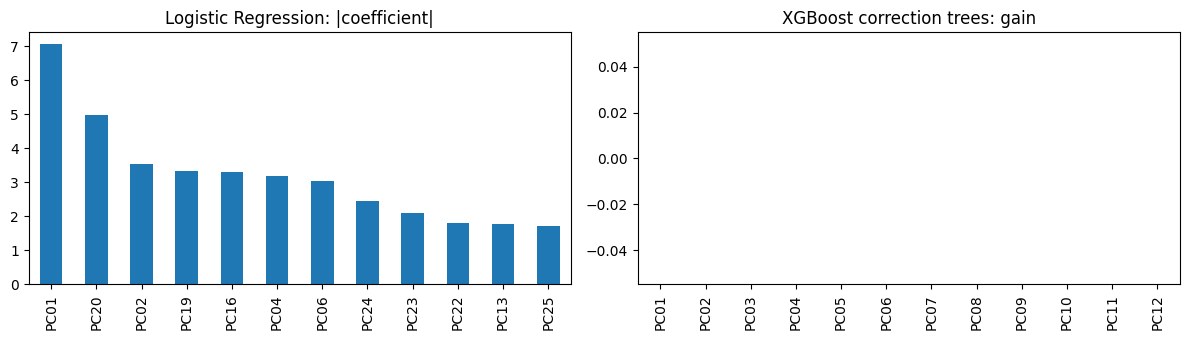

In [ ]:
coef = pd.Series(np.abs(final_lr.coef_[0]), index=features).sort_values(ascending=False)

gain = final_booster.get_score(importance_type='gain')
gain = pd.Series(gain).reindex(features).fillna(0).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
coef.head(12).plot(kind='bar', ax=axes[0])
axes[0].set_title('Logistic Regression: |coefficient|')
gain.head(12).plot(kind='bar', ax=axes[1])
axes[1].set_title('XGBoost correction trees: gain')
plt.tight_layout()
plt.show()

## 18. Save the models

We save everything needed to use the model later:
- `lr_model.joblib`: the Logistic Regression part,
- `lr_xgb_booster.json`: the XGBoost part of the final model,
- `tuned_xgb.json`: the standalone tuned XGBoost (fallback if we want a single model without Logistic Regression),
- `model_info.json`: the parameters, the threshold and the test results.

In [ ]:
os.makedirs('outputs', exist_ok=True)

joblib.dump(final_lr, 'outputs/lr_model.joblib')
final_booster.save_model('outputs/lr_xgb_booster.json')
final_xgb.save_model('outputs/tuned_xgb.json')

info = {
    'threshold': chosen_threshold,
    'features': features,
    'lr_C': best_lrx_params['C'],
    'lr_xgb_params': lrx_params,
    'lr_xgb_rounds': lrx_rounds,
    'tuned_xgb_params': best_xgb_params,
    'tuned_xgb_rounds': int(rounds_xgb * 1.1),
    'cv_results': cv_table.round(6).to_dict(orient='records'),
    'test_results': test_table.round(6).to_dict(orient='records')
}
with open('outputs/model_info.json', 'w') as f:
    json.dump(info, f, indent=2)

print(os.listdir('outputs'))

['lr_model.joblib', 'lr_xgb_booster.json', 'model_info.json', 'tuned_xgb.json']


## 19. Use the saved model (and check it works)

This function loads the saved files and predicts phishing probabilities for new rows that have the same 25 PCA columns. We test it on the first test rows and confirm it gives exactly the same probabilities as before saving.

In [ ]:
def predict_phishing(new_rows, folder='outputs'):
    lr = joblib.load(folder + '/lr_model.joblib')
    booster = xgb.Booster()
    booster.load_model(folder + '/lr_xgb_booster.json')
    with open(folder + '/model_info.json') as f:
        saved = json.load(f)
    values = new_rows[saved['features']].values
    data = xgb.DMatrix(values, base_margin=lr.decision_function(values))
    prob = booster.predict(data)
    label = (prob > saved['threshold']).astype(int)
    return pd.DataFrame({'phishing_probability': prob, 'prediction': label})


check = predict_phishing(test.head(5))
print(check.round(5))
print('Same as before saving:', np.allclose(check['phishing_probability'].values, prob_final[:5], atol=1e-5))

   phishing_probability  prediction
0               1.00000           1
1               0.00008           0
2               1.00000           1
3               1.00000           1
4               0.00001           0
Same as before saving: True


## 20. Summary and notes

- The final model is **Logistic Regression + XGBoost**, chosen by cross-validation on the training data only. The test set was used once, at the end.
- Compare the tables above: the cross-validation table (step 11) is the basis for the choice; the test table (step 14) is the honest final report. The bootstrap intervals (step 15) tell us which differences are real.
- The standalone **Tuned XGBoost** is saved as a fallback if the team prefers a single XGBoost model.

**Things the team must keep in mind**
1. `PC01` alone separates the classes almost perfectly, so this dataset is very easy. High scores here do not guarantee the same performance on new real-world URLs. Test on freshly collected data (including Egyptian/Arabic sites) before claiming generalization.
2. To use the model inside the browser extension / API, every new URL must go through the **same** preprocessing as this data: the same feature extraction, the same scaler and the same PCA object. Keep and version those fitted objects.
3. Explanations (SHAP/LLM) will need the PCA loadings to translate components back into the original features.